# Notebook 3. Dữ liệu chuyên gia và cấp 5 (mạng policy học có giám sát)

Người phụ trách: Trần Quỳnh Hương (cấp 5), sinh dữ liệu và hàm mạng: Nguyễn Trọng Phúc.

Nội dung:
1. Sinh ván chuyên gia trên nhiều máy (mỗi phần một seed), rồi gộp.
2. Thống kê dữ liệu: số ván, tỷ lệ thắng/hòa, độ dài ván, phân bố nhãn.
3. Tạo tập train/val/test chia theo ván, loại thế trùng.
4. Huấn luyện mạng policy, đường cong học, độ chính xác trên val/test.
5. Đánh giá cấp 5: đấu cấp 1–3 và độ chính xác chiến thuật.

Nguồn nhãn: nước đi của bên THẮNG trong ván chuyên gia (50% Alpha-Beta độ sâu 3, 50% MCTS 1000 mô phỏng, nước đầu luôn là cột 4), giống chương 11 của sách.
Nguy cơ: mạng học lại thói quen của hai tác tử chuyên gia, kể cả lỗi của chúng.

Đầu ra: `files/policy_conn.keras` (đẩy lên git), `files/games_*.p`, `files/policy_data.npz` (không đẩy, tạo lại được).

In [1]:
# QUICK = True: chạy thử vài ván, vài epoch để kiểm tra code (ghi vào thư mục con thu_nhanh/)
# QUICK = False: chạy thật theo config.yaml, kết quả dùng cho báo cáo
QUICK = False

import os
if not os.path.exists("config.yaml"):
    raise RuntimeError("Hãy mở Jupyter trong thư mục final_connect_four (nơi có config.yaml).")

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.experiments import setup, summaries_table, with_random_opening, move_times_of
from utils.arena import run_match, format_summary, read_log, first_player_stats
from utils.data import machine_info
import keras
from utils import data, nets, policy_net, tactics
ex = setup(QUICK)
cfg = ex.cfg
print("Cấu hình máy:", machine_info())

Chế độ: chạy thật. Log: results/logs\ | Hình: results\figures\ | Mô hình: files\
Cấu hình máy: {'system': 'Windows', 'release': '11', 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'cpu_count': 16, 'python': '3.13.5'}


## 1. Sinh ván chuyên gia

Ba phần, mỗi phần 1000 ván (`data.games_per_machine`), seed 1, 2, 3 lấy từ `data.seeds`. Tên phần chỉ là nhãn của seed.
Phần nào đã có file đủ số ván thì ô dưới bỏ qua. Mỗi 50 ván lưu một lần nên bị ngắt vẫn giữ được phần đã sinh (nhưng chạy lại sẽ sinh lại phần đó từ đầu).

Lần chạy thật: cả ba phần chạy song song trên cùng một máy (Windows 11, 16 luồng). Phần `phuc` chạy bằng ô dưới; phần `huong` và `thienphuc` chạy bằng dòng lệnh, cùng hàm và tham số:

`python -c "from utils import data; data.generate_games(1000, seed=2, out_path='files/games_huong.p')"`

`python -c "from utils import data; data.generate_games(1000, seed=3, out_path='files/games_thienphuc.p')"`

Thời gian và cấu hình máy của từng phần nằm trong các file `files/games_*.p.json`, tổng hợp ở bảng mục 2.

In [2]:
PARTS_TO_RUN = ["phuc", "huong", "thienphuc"]

data_cfg = cfg["data"]
for part in PARTS_TO_RUN:
    out_path = ex.model(f"games_{part}.p")
    if os.path.exists(out_path + ".json"):
        with open(out_path + ".json", encoding="utf-8") as f:
            meta = json.load(f)
        if meta.get("n_games_done") == meta.get("n_games_target"):
            print("Phần", part, "đã xong, bỏ qua")
            continue
    print("Sinh phần", part, "với seed", data_cfg["seeds"][part])
    data.generate_games(ex.n(data_cfg["games_per_machine"], 6), seed=data_cfg["seeds"][part], out_path=out_path,
                        minimax_depth=data_cfg["minimax_depth"], mcts_simulations=data_cfg["mcts_simulations"])

Phần phuc đã xong, bỏ qua
Phần huong đã xong, bỏ qua
Phần thienphuc đã xong, bỏ qua


## 2. Gộp và thống kê dữ liệu

Ô này cần đủ các file `games_*.p` của mọi phần trong `data.seeds`. Thiếu phần nào thì ô sẽ báo.

In [3]:
paths = []
missing = []
for part in data_cfg["seeds"]:
    path = ex.model(f"games_{part}.p")
    if os.path.exists(path):
        paths.append(path)
    else:
        missing.append(part)
if missing:
    print("CẢNH BÁO: còn thiếu phần", missing, "- kết quả dưới đây chỉ dùng các phần đã có")
games = data.merge_game_files(paths)

# thời gian sinh và cấu hình máy của từng phần (đề yêu cầu khai báo tài nguyên)
rows = []
for path in paths:
    with open(path + ".json", encoding="utf-8") as f:
        meta = json.load(f)
    rows.append({"file": os.path.basename(path), "seed": meta["seed"], "số ván": meta["n_games_done"],
                 "giây": meta["seconds"], "CPU": meta["machine"]["processor"],
                 "số nhân": meta["machine"]["cpu_count"], "hệ điều hành": meta["machine"]["system"]})
gen_table = pd.DataFrame(rows)
gen_table.to_csv(ex.table("nb3_sinh_du_lieu.csv"), index=False, encoding="utf-8-sig")
gen_table

,file,seed,số ván,giây,CPU,số nhân,hệ điều hành
0,games_phuc.p,1,1000,4329.9,"Intel64 Family 6 Model 154 Stepping 3, Genuine...",16,Windows
1,games_huong.p,2,1000,3991.2,"Intel64 Family 6 Model 154 Stepping 3, Genuine...",16,Windows
2,games_thienphuc.p,3,1000,3782.6,"Intel64 Family 6 Model 154 Stepping 3, Genuine...",16,Windows


In [4]:
red = 0
yellow = 0
draw = 0
lengths = []
for game in games:
    if game["reward"] == 1:
        red += 1
    elif game["reward"] == -1:
        yellow += 1
    else:
        draw += 1
    lengths.append(len(game["history"]))
n = len(games)
print(f"{n} ván | đỏ thắng {red / n:.3f}, vàng thắng {yellow / n:.3f}, hòa {draw / n:.3f}")
print(f"độ dài ván: trung bình {np.mean(lengths):.1f} nước, ngắn nhất {min(lengths)}, dài nhất {max(lengths)}")

3000 ván | đỏ thắng 0.479, vàng thắng 0.430, hòa 0.091
độ dài ván: trung bình 33.3 nước, ngắn nhất 7, dài nhất 42


## 3. Tập dữ liệu cho mạng policy

Mẫu = (thế cờ nhìn từ người sắp đi, cột người thắng đã đi). Chia train/val/test = 80/10/10 **theo ván**, loại cặp trùng trong từng tập và loại khỏi val/test các thế đã có trong train.
Tập train được thêm bản lật gương (Connect Four đối xứng trái phải: cột c thành cột 8 − c), val và test giữ nguyên.

In [5]:
policy_set = data.make_dataset(games, kind="policy", seed=0, mirror=cfg["train_policy"]["mirror"])
print(data.describe_dataset(policy_set))
data.save_dataset(policy_set, ex.model("policy_data.npz"))

# phân bố nhãn: nếu một cột chiếm quá nhiều thì mạng dễ học lệch về cột đó
counts = np.bincount(policy_set["y_train"], minlength=7)
label_table = pd.DataFrame({"cột": range(1, 8), "số mẫu train": counts,
                            "tỷ lệ": np.round(counts / counts.sum(), 3)})
# mốc so sánh: luôn đoán cột xuất hiện nhiều nhất trong train
majority = int(np.argmax(counts))
baseline = float(np.mean(policy_set["y_test"] == majority))
print(f"Mốc 'luôn đoán cột {majority + 1}': độ chính xác trên test = {baseline:.3f}")
label_table

policy: 2727 ván | train 50628, val 2805, test 2830 mẫu
Mốc 'luôn đoán cột 1': độ chính xác trên test = 0.189


,cột,số mẫu train,tỷ lệ
0,1,8547,0.169
1,2,8029,0.159
2,3,7398,0.146
3,4,2680,0.053
4,5,7398,0.146
5,6,8029,0.159
6,7,8547,0.169


## 4. Huấn luyện mạng policy

Kiến trúc của chương 11 sách (Conv 128 bộ lọc 4×4, Dense 64, Dense 64, Softmax 7), Adam, sparse categorical cross-entropy.
Siêu tham số lấy từ `train_policy` trong `config.yaml`. Chỉ nhìn tập val trong lúc huấn luyện; tập test chỉ dùng một lần ở cuối.

Dừng sớm: lần chạy đầu (30 epoch, không lật gương, hình `nb3_duong_cong_policy_lan1_khong_dung_som.png`) có val_loss thấp nhất ở epoch 6 rồi tăng liên tục, tức mạng học thuộc tập train.
Vì vậy huấn luyện dừng khi val_loss không giảm trong `patience` epoch liền và giữ trọng số ở epoch có val_loss thấp nhất. Quyết định này chỉ dựa vào tập val.

In [6]:
train_cfg = cfg["train_policy"]
keras.utils.set_random_seed(0)
policy_path = ex.model("policy_conn.keras")
model, report = policy_net.train_policy(games, path=policy_path, epochs=ex.n(train_cfg["epochs"], 2),
                                        batch_size=train_cfg["batch_size"],
                                        learning_rate=train_cfg["learning_rate"], seed=0, verbose=2,
                                        mirror=train_cfg["mirror"], patience=train_cfg["patience"])
print(f"Chạy {report['epochs_run']} epoch, giữ trọng số epoch {report['best_epoch']} (val_loss thấp nhất)")
print(f"Huấn luyện {report['train_seconds']} giây | val acc {report['val_accuracy']:.3f} | "
      f"test acc {report['test_accuracy']:.3f} (mốc luôn đoán một cột: {baseline:.3f})")
print("Số tham số của mạng:", model.count_params())

Epoch 1/30
396/396 - 6s - 16ms/step - accuracy: 0.3884 - loss: 1.5024 - val_accuracy: 0.4756 - val_loss: 1.2709
Epoch 2/30
396/396 - 4s - 10ms/step - accuracy: 0.4755 - loss: 1.2905 - val_accuracy: 0.4980 - val_loss: 1.2163
Epoch 3/30
396/396 - 4s - 9ms/step - accuracy: 0.4973 - loss: 1.2429 - val_accuracy: 0.5091 - val_loss: 1.2004
Epoch 4/30
396/396 - 4s - 10ms/step - accuracy: 0.5142 - loss: 1.2067 - val_accuracy: 0.5055 - val_loss: 1.1938
Epoch 5/30
396/396 - 4s - 9ms/step - accuracy: 0.5286 - loss: 1.1729 - val_accuracy: 0.5062 - val_loss: 1.1924
Epoch 6/30
396/396 - 4s - 10ms/step - accuracy: 0.5431 - loss: 1.1398 - val_accuracy: 0.5094 - val_loss: 1.1946
Epoch 7/30
396/396 - 4s - 10ms/step - accuracy: 0.5552 - loss: 1.1096 - val_accuracy: 0.5066 - val_loss: 1.1960
Epoch 8/30
396/396 - 4s - 9ms/step - accuracy: 0.5703 - loss: 1.0794 - val_accuracy: 0.5166 - val_loss: 1.2024
Epoch 9/30
396/396 - 4s - 9ms/step - accuracy: 0.5826 - loss: 1.0501 - val_accuracy: 0.5116 - val_loss: 1.2

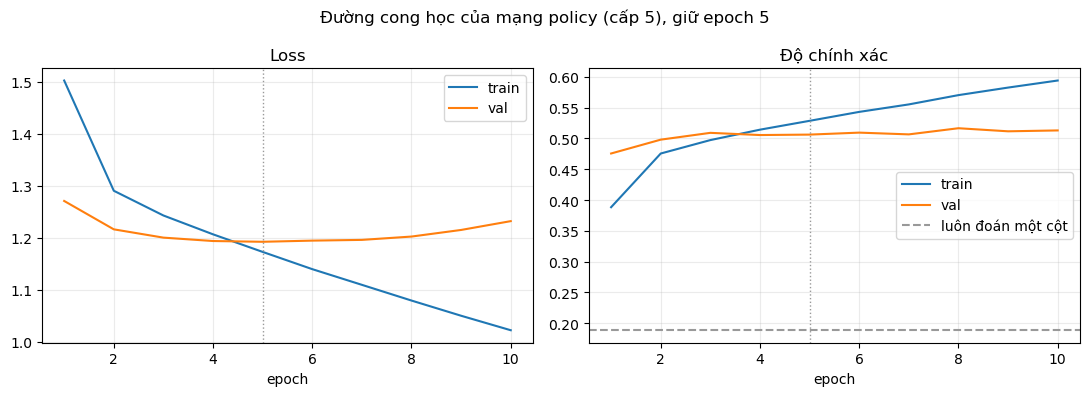

In [7]:
curve = report["curve"]
epochs = range(1, len(curve["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, curve["loss"], label="train")
axes[0].plot(epochs, curve["val_loss"], label="val")
axes[0].set_title("Loss")
axes[1].plot(epochs, curve["accuracy"], label="train")
axes[1].plot(epochs, curve["val_accuracy"], label="val")
axes[1].axhline(baseline, color="#999999", linestyle="--", label="luôn đoán một cột")
axes[1].set_title("Độ chính xác")
for ax in axes:
    ax.axvline(report["best_epoch"], color="#999999", linestyle=":", linewidth=1)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f"Đường cong học của mạng policy (cấp 5), giữ epoch {report['best_epoch']}")
fig.tight_layout()
fig.savefig(ex.fig("nb3_duong_cong_policy.png"), dpi=150)

## 5. Đánh giá cấp 5

Cấp 5 luôn đi cột có xác suất cao nhất nên là tác tử tất định; mỗi ván mở đầu bằng 2 nước ngẫu nhiên có seed để các ván khác nhau.
Đây là kiểm tra nhanh sau huấn luyện; số liệu chính thức của cấp 5 lấy ở giải đấu nb6.

In [8]:
n_games = ex.n(100, 6)
opening = cfg["tournament"]["opening_random_moves"]
log_path = ex.log("nb3_danh_gia_cap5.jsonl")
cap5 = with_random_opening(ex.agent("cap5"), opening)

summaries = []
for k, name in enumerate(["cap1", "cap2", "cap3"]):
    s = run_match(cap5, with_random_opening(ex.agent(name), opening), "cap5", name, n_games,
                  seed=600 + k, log_path=log_path)
    summaries.append(s)
    print(format_summary(s))
cap5_table = summaries_table(summaries)
cap5_table.to_csv(ex.table("nb3_danh_gia_cap5.csv"), index=False, encoding="utf-8-sig")
cap5_table

cap5 vs cap1: 87-0-13 (thắng-hòa-thua), score 0.870 [0.790, 0.922], thời gian TB 1.2 ms, p95 1.5 ms
cap5 vs cap2: 8-4-88 (thắng-hòa-thua), score 0.100 [0.055, 0.174], thời gian TB 1.2 ms, p95 1.9 ms
cap5 vs cap3: 7-14-79 (thắng-hòa-thua), score 0.140 [0.085, 0.221], thời gian TB 1.7 ms, p95 2.6 ms


,tác tử,đối thủ,số ván,thắng,hòa,thua,score,Wilson 95%,TB (ms),p95 (ms),xử thua
0,cap5,cap1,100,87,0,13,0.87,"[0.790, 0.922]",1.2,1.5,0
1,cap5,cap2,100,8,4,88,0.10,"[0.055, 0.174]",1.2,1.9,0
2,cap5,cap3,100,7,14,79,0.14,"[0.085, 0.221]",1.7,2.6,0


In [9]:
tactics_path = ex.model("tactics.json")
if os.path.exists(tactics_path):
    positions = tactics.load_tactics(tactics_path)
    move_fn, info_fn = ex.agent("cap5")
    print("Độ chính xác chiến thuật của cấp 5:", tactics.score_agent(move_fn, positions))
else:
    print("Chưa có", tactics_path, "- chạy mục 1 của nb2 (hoặc chép file từ máy kia) rồi chạy lại ô này.")

Độ chính xác chiến thuật của cấp 5: {'win_now': 0.14285714285714285, 'must_block': 0.46153846153846156, 'double_threat': 0.3076923076923077, 'all': 0.3}
